# Pozo potencial finito
### Física Electrónica - UTN FRA
*Cuaderno interactivo adaptado para Google Colab.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)


#La ecuación de Schrödinger independiente del tiempo

1. La ecuación de Schrödinger independiente del tiempo para una partícula de masa m en un potencial V(x) en una dimensión:

$
-\frac{{\hbar^2}}{{2m}}\frac{{d^2\psi}}{{dx^2}} + V(x)\psi = E\psi
$

Donde:
- \(\hbar\) es la constante de Planck reducida (\(\hbar = \frac{{h}}{{2\pi}}\)).
- \(\psi\) es la función de onda de la partícula.
- E es la energía total de la partícula.

2. La ecuación de Schrödinger dependiente del tiempo para una partícula de masa m en un potencial V(x) en una dimensión:

$
i\hbar\frac{{\partial\psi}}{{\partial t}} = -\frac{{\hbar^2}}{{2m}}\frac{{d^2\psi}}{{dx^2}} + V(x)\psi
$

Donde:
- \(\psi\) es la función de onda de la partícula.
- t es el tiempo.
- \(\hbar\) es la constante de Planck reducida.

3. Solución general de la ecuación de Schrödinger independiente del tiempo para una partícula libre en una dimensión:

$
\psi(x) = Ae^{ikx} + Be^{-ikx}
$

Donde:
- A y B son constantes determinadas por las condiciones de contorno.
- k es el número de onda, relacionado con la energía de la partícula a través de la relación \(E = \frac{{\hbar^2k^2}}{{2m}}\).

Estas son solo algunas de las fórmulas asociadas a la ecuación de Schrödinger. La ecuación completa y sus soluciones dependen del sistema en particular que se esté estudiando.

#pozo de potencial finito:

Un pozo de potencial finito es un concepto en la mecánica cuántica que describe una región en la cual una partícula cuántica se encuentra confinada debido a un cambio abrupto en el potencial.

El potencial en un pozo de potencial finito se caracteriza por tener un valor constante en una región limitada y distinto de cero, mientras que en las regiones adyacentes el potencial es mayor o menor. Esta discontinuidad en el potencial crea una barrera que restringe la partícula cuántica a una región finita.

Dentro del pozo de potencial finito, la ecuación de Schrödinger se resuelve para obtener las funciones de onda y los niveles de energía permitidos para la partícula confinada. Estos niveles de energía son discretos y determinan los estados estacionarios en los que la partícula puede existir dentro del pozo.

El comportamiento de la partícula cuántica en un pozo de potencial finito es notablemente diferente al de una partícula en una región con potencial infinito o nulo. Por ejemplo, existen energías permitidas para la partícula dentro del pozo, mientras que en una región con potencial infinito no existen estados estacionarios.

El estudio de los pozos de potencial finito es relevante en diversos campos de la física, como la física de semiconductores, la física nuclear y la óptica cuántica, ya que permite comprender cómo las partículas cuánticas se comportan en regiones con cambios bruscos en el potencial
```



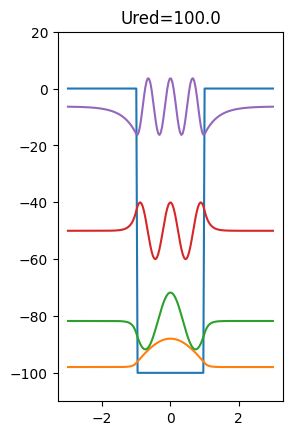

In [8]:
# Soluciones
import warnings
warnings.filterwarnings('ignore')  # Ignorar advertencias

import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as optim

# Definición de una función para encontrar las soluciones pares
def find_even_solutions(Ured, a):
    # Construir el conjunto de intervalos con cotangente negativa
    kamax = np.sqrt(Ured)
    nintervals = int(kamax / 3.1415926 + 1)
    intervals = [[3.1415926 * (i) + 1.e-3, min(3.1415926 * (i + .5), kamax)]
                 for i in range(nintervals)]
    sols = []

    # Bucle sobre los intervalos
    for i in intervals:
        if i[1] < i[0]:
            continue
        try:
            # Encontrar la solución en el intervalo utilizando el método de Brent
            newsol = optim.brentq(lambda x: (np.tan(x) ** 2 - Ured / x ** 2 + 1), i[0], i[1])

            # Verificar la solución
            if np.abs(np.tan(newsol) - np.sqrt(Ured / newsol ** 2 - 1)) > 1e-3:
                continue
        except:
            continue

        yetfound = False
        for q in sols:
            if np.abs(q - newsol) < 1e-3:
                yetfound = True
                break
        if not yetfound:
            sols.append(newsol)

    return np.array([s / a for s in sols])

def psi_even(x, k, Ured, a):
    alpha = np.sqrt(Ured / a ** 2 - k ** 2)
    if x < 0:
        x = -x
    if x < a:
        return (.1 * Ured / a ** 2) * np.cos(k * x) + k ** 2 - Ured / a ** 2
    else:
        return (.1 * Ured / a ** 2) * np.cos(k * a) * np.exp(-alpha * (x - a)) + k ** 2 - Ured / a ** 2

%matplotlib inline
def makeplot_even_sol(Ured,a):
  xvals=np.linspace(-3,3,160)
  # Definimos un arreglo de valores equiespaciados en el rango de -3 a 3 con 160 puntos
  # para representar el eje x en el gráfico

  psis=[np.array([psi_even(x,k,Ured,a) for x in xvals])
    for k in find_even_solutions(Ured,a)]
  # Calculamos las funciones de onda psi para soluciones pares utilizando la función
  # 'psi_even' con distintos valores de 'k' para cada solución, en el rango de 'xvals'
  # y almacenamos los resultados en una lista llamada 'psis'.

  f1=plt.subplot(121)

  # subplot como el objeto en el que se dibujarán los gráficos.

  pot=np.array([ -Ured/a**2 if abs(x)<a else 0. for x in xvals])
  # Calculamos el potencial 'pot' en función de los valores de 'xvals'. Si el valor absoluto
  # de 'x' es menor que 'a', el potencial es igual a '-Ured/a**2', de lo contrario es cero.

  f1.plot(xvals,pot)
  # Dibujamos el gráfico del potencial en función de 'xvals' en el primer subplot.

  for psik in psis:
    f1.plot(xvals,psik)
  # Dibujamos el gráfico de cada función de onda 'psik' en función de 'xvals' en el primer subplot.

  plt.ylim(-1.1*Ured/a**2,.2*Ured/a**2)
  # Establecemos los límites del eje y en el primer subplot.

  plt.title("Ured="+str(Ured))
  # Establecemos el título del primer subplot.

  f2=plt.subplot(121)
  # Seleccionamos el segundo subplot como el objeto en el que se dibujarán los gráficos.

  sols = find_even_solutions(Ured,a)
  # Calculamos las soluciones pares utilizando la función 'find_even_solutions'.

  kas=np.linspace(0.01,np.sqrt(Ured)/a+1,2000)
  # Creamos un arreglo de valores equiespaciados en el rango de 0.01 a la raíz cuadrada de
  # 'Ured' dividido por 'a' más 1, con 2000 puntos, para representar el eje x en el segundo
  # subplot.

  gtan=np.array([np.tan(ka) for ka in kas ])
  # Calculamos la tangente de cada valor de 'ka' en 'kas' y almacenamos los resultados en
  # un arreglo llamado 'gtan'.

  ghyp=np.array([np.sqrt(Ured/ka**2-1) for ka in kas ])
  # Calculamos la raíz cuadrada de 'Ured/ka**2-1' para cada valor de 'ka' en 'kas' y almacenamos
  # los resultados en un arreglo llamado 'ghyp'.

  #f2.plot(kas,gtan)
  # Dibujamos el gráfico
makeplot_even_sol(100.,1)

In [ ]:
import warnings
warnings.filterwarnings('ignore')  # Ignorar advertencias

import matplotlib.pyplot as plt
import numpy as np
import scipy.optimize as optim

# Definición de una función para encontrar las soluciones pares
def find_even_solutions(Ured, a):
    # Construir el conjunto de intervalos con cotangente negativa
    kamax = np.sqrt(Ured)
    nintervals = int(kamax / 3.1415926 + 1)
    intervals = [[3.1415926 * (i) + 1.e-3, min(3.1415926 * (i + .5), kamax)]
                 for i in range(nintervals)]
    sols = []

    # Bucle sobre los intervalos
    for i in intervals:
        if i[1] < i[0]:
            continue
        try:
            # Encontrar la solución en el intervalo utilizando el método de Brent
            newsol = optim.brentq(lambda x: (np.tan(x) ** 2 - Ured / x ** 2 + 1), i[0], i[1])

            # Verificar la solución
            if np.abs(np.tan(newsol) - np.sqrt(Ured / newsol ** 2 - 1)) > 1e-3:
                continue
        except:
            continue

        yetfound = False
        for q in sols:
            if np.abs(q - newsol) < 1e-3:
                yetfound = True
                break
        if not yetfound:
            sols.append(newsol)

    return np.array([s / a for s in sols])

def psi_even(x, k, Ured, a):
    alpha = np.sqrt(Ured / a ** 2 - k ** 2)
    if x < 0:
        x = -x
    if x < a:
        return (.1 * Ured / a ** 2) * np.cos(k * x) + k ** 2 - Ured / a ** 2
    else:
        return (.1 * Ured / a ** 2) * np.cos(k * a) * np.exp(-alpha * (x - a)) + k ** 2 - Ured / a ** 2

%matplotlib inline
def makeplot_even_sol(Ured, a):
    xvals = np.linspace(-3, 3, 160)
    # Definimos un arreglo de valores equiespaciados en el rango de -3 a 3 con 160 puntos
    # para representar el eje x en el gráfico

    psis = [np.array([psi_even(x, k, Ured, a) for x in xvals])
            for k in find_even_solutions(Ured, a)]
    # Calculamos las funciones de onda psi para soluciones pares utilizando la función
    # 'psi_even' con distintos valores de 'k' para cada solución, en el rango de 'xvals'
    # y almacenamos los resultados en una lista llamada 'psis'.

    fig, (f1, f2) = plt.subplots(1, 2, figsize=(12, 6))
    # Creamos una figura con una matriz de 1x2 y seleccionamos los subplots f1 y f2.

    pot = np.array([-Ured / a ** 2 if abs(x) < a else 0. for x in xvals])
    # Calculamos el potencial 'pot' en función de los valores de 'xvals'. Si el valor absoluto
    # de 'x' es menor que 'a', el potencial es igual a '-Ured/a**2', de lo contrario es cero.

    f1.plot(xvals, pot)
    # Dibujamos el gráfico del potencial en función de 'xvals' en el primer subplot.

    for psik in psis:
        f1.plot(xvals, psik)
    # Dibujamos el gráfico de cada función de onda 'psik' en función de 'xvals' en el primer subplot.

    f1.set_ylim(-1.1 * Ured / a ** 2, .2 * Ured / a ** 2)
    # Establecemos los límites del eje y en el primer subplot.

    f1.set_title("Ured=" + str(Ured))
    # Establecemos el título del primer subplot.

    sols = find_even_solutions(Ured, a)
    # Calculamos las soluciones pares utilizando la función 'find_even_solutions'.

    kas = np.linspace(0.01, np.sqrt(Ured) / a + 1, 2000)
    # Creamos un arreglo de valores equiespaciados en el rango de 0.01 a la raíz cuadrada de
    # 'Ured' dividido por 'a' más 1, con 2000 puntos, para representar el eje x en el segundo
    # subplot.

    gtan = np.array([np.tan(ka) for ka in kas])
    # Calculamos la tangente de cada valor de 'ka' en 'kas' y almacenamos los resultados en
    # un arreglo llamado 'gtan'.

    ghyp = np.array([np.sqrt(Ured / ka ** 2 - 1) for ka in kas])
    # Calculamos la raíz cuadrada de 'Ured/ka**2-1' para cada valor de 'ka' en 'kas' y almacenamos
    # los resultados en un arreglo llamado 'ghyp'.

    f2.plot(kas, gtan)
    # Dibujamos el gráfico de 'gtan' en función de 'kas' en el segundo subplot.

    f2.plot(kas, ghyp)
    # Dibujamos el gráfico de 'ghyp' en función de 'kas' en el segundo subplot.

    f2.set_ylim(-10, 10)
    # Establecemos los límites del eje y en el segundo subplot.

    f2.set_title("Relaciones de dispersión")
    # Establecemos el título del segundo subplot.

    plt.tight_layout()
    # Ajustamos el diseño de los subplots para evitar superposiciones.

    plt.show()
    # Mostramos la figura completa.

makeplot_even_sol(1, 1)


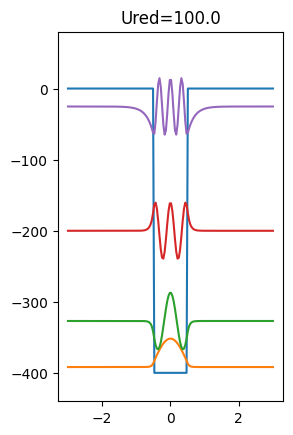